In [1]:
!pip install -q pandas numpy scikit-learn matplotlib

In [2]:
import numpy as np
import pandas as pd

# Membuat data simulasi
np.random.seed(42)

jumlah_data = 360

jenis_gangguan = [
    "Pertanian",
    "Pertambangan",
    "Penebangan",
    "Pembangunan jalan",
    "Kebakaran",
    "Gangguan alami"
]

data = []

for i in range(jumlah_data):
    kategori = jenis_gangguan[i % len(jenis_gangguan)]

    kehilangan_vegetasi = np.random.uniform(10, 100)
    perubahan_kelembapan = np.random.uniform(-1, 1)
    jarak_jalan = np.random.uniform(0, 20)
    indeks_kebakaran = np.random.uniform(0, 1)
    gangguan_tanah = np.random.uniform(0, 1)
    perubahan_kanopi = np.random.uniform(0, 1)

    data.append({
        "id_alert": f"AL-{i+1:04d}",
        "kehilangan_vegetasi_pct": kehilangan_vegetasi,
        "perubahan_kelembapan": perubahan_kelembapan,
        "jarak_jalan_km": jarak_jalan,
        "indeks_kebakaran": indeks_kebakaran,
        "gangguan_tanah": gangguan_tanah,
        "perubahan_kanopi": perubahan_kanopi,
        "jenis_gangguan": kategori
    })

df = pd.DataFrame(data)

df.head()

,id_alert,kehilangan_vegetasi_pct,perubahan_kelembapan,jarak_jalan_km,indeks_kebakaran,gangguan_tanah,perubahan_kanopi,jenis_gangguan
0,AL-0001,43.708611,0.901429,14.639879,0.598658,0.156019,0.155995,Pertanian
1,AL-0002,15.227525,0.732352,12.022300,0.708073,0.020584,0.969910,Pertambangan
2,AL-0003,84.919838,-0.575322,3.636499,0.183405,0.304242,0.524756,Penebangan
3,AL-0004,48.875052,-0.417542,12.237058,0.139494,0.292145,0.366362,Pembangunan jalan
4,AL-0005,51.046299,0.570352,3.993476,0.514234,0.592415,0.046450,Kebakaran


In [3]:
# 1. Melihat ukuran dataset
print("Jumlah baris dan kolom:", df.shape)

# 2. Melihat informasi dataset
print("\nInformasi dataset:")
df.info()

# 3. Memeriksa data kosong
print("\nJumlah data kosong:")
print(df.isnull().sum())

# 4. Melihat statistik fitur numerik
print("\nStatistik dataset:")
display(df.describe())

# 5. Melihat jumlah data pada setiap kategori
print("\nDistribusi jenis gangguan:")
print(df["jenis_gangguan"].value_counts())

Jumlah baris dan kolom: (360, 8)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_alert                 360 non-null    object 
 1   kehilangan_vegetasi_pct  360 non-null    float64
 2   perubahan_kelembapan     360 non-null    float64
 3   jarak_jalan_km           360 non-null    float64
 4   indeks_kebakaran         360 non-null    float64
 5   gangguan_tanah           360 non-null    float64
 6   perubahan_kanopi         360 non-null    float64
 7   jenis_gangguan           360 non-null    object 
dtypes: float64(6), object(2)
memory usage: 22.6+ KB

Jumlah data kosong:
id_alert                   0
kehilangan_vegetasi_pct    0
perubahan_kelembapan       0
jarak_jalan_km             0
indeks_kebakaran           0
gangguan_tanah             0
perubahan_kanopi           0
jenis_gangguan            

,kehilangan_vegetasi_pct,perubahan_kelembapan,jarak_jalan_km,indeks_kebakaran,gangguan_tanah,perubahan_kanopi
count,360.000000,360.000000,360.000000,360.000000,360.000000,360.000000
mean,54.613362,0.010814,9.810778,0.518107,0.478233,0.507927
std,26.579959,0.572339,5.970063,0.279015,0.303573,0.288971
min,10.496991,-0.993563,0.139043,0.007563,0.004940,0.004632
25%,30.584108,-0.486554,4.488160,0.259508,0.180041,0.271246
50%,55.528362,0.047577,9.726232,0.514526,0.464765,0.512020
75%,78.548007,0.493867,14.789025,0.753669,0.749893,0.753169
max,99.947235,0.993749,19.882787,0.999718,0.998348,0.996697



Distribusi jenis gangguan:
jenis_gangguan
Pertanian            60
Pertambangan         60
Penebangan           60
Pembangunan jalan    60
Kebakaran            60
Gangguan alami       60
Name: count, dtype: int64


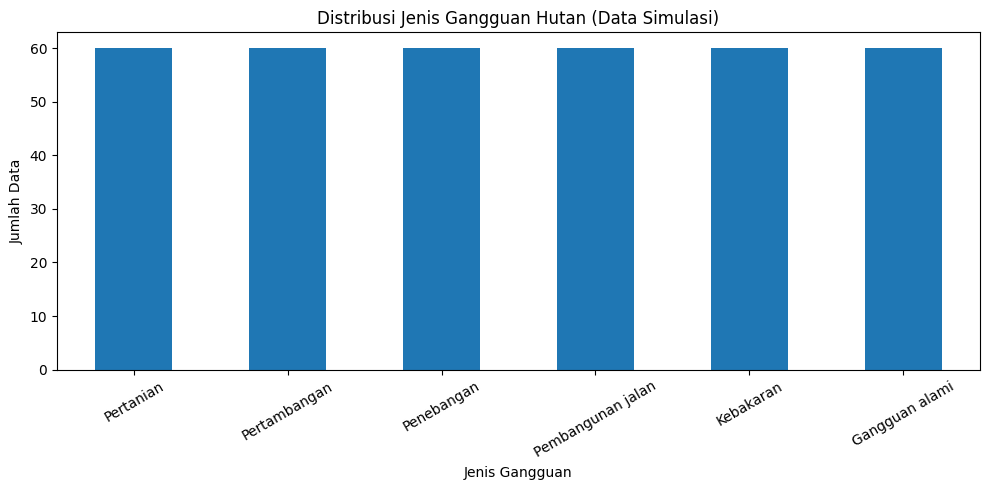

In [4]:
import matplotlib.pyplot as plt

# Menghitung jumlah setiap kategori
jumlah_kategori = df["jenis_gangguan"].value_counts()

# Membuat grafik batang
plt.figure(figsize=(10, 5))
jumlah_kategori.plot(kind="bar")

plt.title("Distribusi Jenis Gangguan Hutan (Data Simulasi)")
plt.xlabel("Jenis Gangguan")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [5]:
# Membuat ulang dataset dengan pola simulasi per kategori
np.random.seed(42)

data = []

pola = {
    "Pertanian":           (65, -0.25, 3.0, 0.10, 0.60, 0.70),
    "Pertambangan":        (75, -0.15, 4.0, 0.10, 0.90, 0.85),
    "Penebangan":          (45, -0.05, 5.0, 0.10, 0.45, 0.55),
    "Pembangunan jalan":   (55, -0.10, 1.5, 0.10, 0.65, 0.65),
    "Kebakaran":           (80, -0.65, 6.0, 0.85, 0.60, 0.90),
    "Gangguan alami":      (30,  0.05, 9.0, 0.10, 0.25, 0.30)
}

for i in range(360):
    kategori = jenis_gangguan[i % len(jenis_gangguan)]
    veg, lembap, jalan, api, tanah, kanopi = pola[kategori]

    data.append({
        "id_alert": f"AL-{i+1:04d}",
        "kehilangan_vegetasi_pct": np.clip(np.random.normal(veg, 10), 0, 100),
        "perubahan_kelembapan": np.clip(np.random.normal(lembap, 0.15), -1, 1),
        "jarak_jalan_km": np.clip(np.random.normal(jalan, 1.5), 0, 20),
        "indeks_kebakaran": np.clip(np.random.normal(api, 0.12), 0, 1),
        "gangguan_tanah": np.clip(np.random.normal(tanah, 0.12), 0, 1),
        "perubahan_kanopi": np.clip(np.random.normal(kanopi, 0.10), 0, 1),
        "jenis_gangguan": kategori
    })

df = pd.DataFrame(data)

display(df.head())
print("Jumlah data:", len(df))

,id_alert,kehilangan_vegetasi_pct,perubahan_kelembapan,jarak_jalan_km,indeks_kebakaran,gangguan_tanah,perubahan_kanopi,jenis_gangguan
0,AL-0001,69.967142,-0.270740,3.971533,0.282764,0.571902,0.676586,Pertanian
1,AL-0002,90.792128,-0.034885,3.295788,0.165107,0.844390,0.803427,Pertambangan
2,AL-0003,47.419623,-0.336992,2.412623,0.032525,0.328460,0.581425,Penebangan
3,AL-0004,45.919759,-0.311846,3.698473,0.072907,0.658103,0.507525,Pembangunan jalan
4,AL-0005,74.556173,-0.633362,4.273510,0.895084,0.527923,0.870831,Kebakaran


Jumlah data: 360


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Memilih fitur untuk prediksi
fitur = [
    "kehilangan_vegetasi_pct",
    "perubahan_kelembapan",
    "jarak_jalan_km",
    "indeks_kebakaran",
    "gangguan_tanah",
    "perubahan_kanopi"
]

X = df[fitur]
y = df["jenis_gangguan"]

# Membagi data menjadi data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Membuat dan melatih model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model berhasil dilatih!")
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Model berhasil dilatih!
Jumlah data latih: 270
Jumlah data uji: 90


In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Melakukan prediksi pada data uji
y_pred = model.predict(X_test)

# Menghitung metrik evaluasi
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("=== HASIL EVALUASI MODEL ===")
print(f"Accuracy  : {accuracy:.2%}")
print(f"Precision : {precision:.2%}")
print(f"Recall    : {recall:.2%}")
print(f"Macro F1  : {f1:.2%}")

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, zero_division=0))

=== HASIL EVALUASI MODEL ===
Accuracy  : 85.56%
Precision : 85.23%
Recall    : 85.56%
Macro F1  : 85.31%

=== CLASSIFICATION REPORT ===
                   precision    recall  f1-score   support

   Gangguan alami       1.00      1.00      1.00        15
        Kebakaran       1.00      1.00      1.00        15
Pembangunan jalan       0.71      0.67      0.69        15
       Penebangan       0.93      0.93      0.93        15
     Pertambangan       0.82      0.93      0.88        15
        Pertanian       0.64      0.60      0.62        15

         accuracy                           0.86        90
        macro avg       0.85      0.86      0.85        90
     weighted avg       0.85      0.86      0.85        90



<Figure size 1000x700 with 0 Axes>

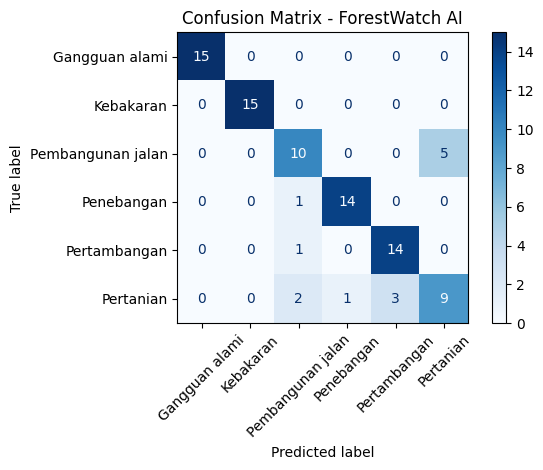

In [8]:
plt.figure(figsize=(10, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Confusion Matrix - ForestWatch AI")
plt.tight_layout()
plt.show()

In [9]:
# Data baru untuk diuji
data_baru = pd.DataFrame([{
    "kehilangan_vegetasi_pct": 78,
    "perubahan_kelembapan": -0.65,
    "jarak_jalan_km": 6.0,
    "indeks_kebakaran": 0.85,
    "gangguan_tanah": 0.60,
    "perubahan_kanopi": 0.90
}])

# Melakukan prediksi
hasil_prediksi = model.predict(data_baru[fitur])

# Menampilkan hasil
print("=== HASIL PREDIKSI FORESTWATCH AI ===")
print("Kehilangan vegetasi:", data_baru.iloc[0]["kehilangan_vegetasi_pct"], "%")
print("Indeks kebakaran:", data_baru.iloc[0]["indeks_kebakaran"])
print("Prediksi jenis gangguan:", hasil_prediksi[0])

=== HASIL PREDIKSI FORESTWATCH AI ===
Kehilangan vegetasi: 78.0 %
Indeks kebakaran: 0.85
Prediksi jenis gangguan: Kebakaran


In [10]:
probabilitas = model.predict_proba(data_baru[fitur])[0]

hasil_probabilitas = pd.DataFrame({
    "Jenis Gangguan": model.classes_,
    "Probabilitas (%)": probabilitas * 100
})

hasil_probabilitas = hasil_probabilitas.sort_values(
    by="Probabilitas (%)",
    ascending=False
)

display(hasil_probabilitas.round(2))

,Jenis Gangguan,Probabilitas (%)
1,Kebakaran,100.0
0,Gangguan alami,0.0
2,Pembangunan jalan,0.0
3,Penebangan,0.0
4,Pertambangan,0.0
5,Pertanian,0.0


In [11]:
# Menyimpan dataset simulasi
df.to_csv("deforestation_alerts.csv", index=False)

# Menyimpan hasil prediksi
hasil_akhir = data_baru.copy()
hasil_akhir["prediksi_jenis_gangguan"] = hasil_prediksi[0]
hasil_akhir.to_csv("hasil_prediksi.csv", index=False)

print("Dataset dan hasil prediksi berhasil disimpan!")

Dataset dan hasil prediksi berhasil disimpan!


In [12]:
from google.colab import files

files.download("deforestation_alerts.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
files.download("hasil_prediksi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>